# Spectraverse v1.0.3 data overview

Source: `data/raw/spectraverse/spectraverse-1.0.3/spectraverse-1.0.3.mgf`
(md5 `52ed27db2d5b764a636fb2ce246004aa`, 464,228 records). Processed with the
[v1.0.3 commands](../../preproc_scripts/README.md#spectraverse-v103) into
`data/proc/spectraverse_1_0_3/`; benchmark folds in `data/split/spectraverse_benchmark_1_0_3/cv0-cv9`.

Known caveats of the stored `spec_df.pkl` (see the
[Spectraverse hub](../../docs/workstreams/spectraverse.md#open-threads)):
- `inst_type == 'Other'` is the MGF `INSTRUMENT_TYPE=iontrap` block. The parser now maps it to `IT`,
  but this pickle was built before the fix; rerun step 2 to relabel it.
- `ion_mode` is correct here (`[M+Cl]-`, `[M+HCOOH-H]-`, `[M+CH3COOH-H]-` are `N`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")  # mol_df pickles hold RDKit Mol objects from a newer RDKit

DATA = Path("../../data")
SPV_DP = DATA / "proc/spectraverse_1_0_3"
SPV_OLD_DP = DATA / "proc/spectraverse_1_0_2"
SPLIT_DP = DATA / "split/spectraverse_benchmark_1_0_3"

## Load

In [2]:
spectraverse_spec_df = pd.read_pickle(SPV_DP / "spec_df.pkl")
spectraverse_mol_df = pd.read_pickle(SPV_DP / "mol_df.pkl").drop(columns=["mol"])
spectraverse_df = spectraverse_spec_df.merge(spectraverse_mol_df, on="mol_id", how="left")
assert spectraverse_df["inchikey_s"].notnull().all()

print(f"Spectra:              {len(spectraverse_spec_df):,}")
print(f"mol_id values:        {spectraverse_spec_df['mol_id'].nunique():,}")
print(f"2D InChIKeys:         {spectraverse_df['inchikey_s'].nunique():,}")
print(f"(mol_id, adduct):     {spectraverse_spec_df.groupby(['mol_id', 'prec_type']).ngroups:,}")
spectraverse_spec_df.head()

Spectra:              464,228
mol_id values:        44,300
2D InChIKeys:         44,234
(mol_id, adduct):     78,628


,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,ace_extra_1,ace_extra_2,nce,nce_extra_1,nce_extra_2,ce_type,prec_mz,peaks,ri,group_id
0,0,13293,[M-H]-,ORB,CID,MS2,N,spectraverse,1,NA,...,NaN,NaN,NaN,NaN,NaN,single,283.1551,"[(41.003009, 0.08621000000000001), (41.005077,...",NaN,31328
1,1,28691,[M-H]-,ORB,CID,MS2,N,spectraverse,3,NA,...,NaN,NaN,NaN,NaN,NaN,single,328.11905,"[(40.256272, 0.00212), (41.003102, 0.001), (41...",NaN,60952
2,2,28691,[M-H]-,ORB,CID,MS2,N,spectraverse,4,NA,...,NaN,NaN,NaN,NaN,NaN,single,328.11905,"[(41.998303, 0.0086), (61.988184, 0.00451), (8...",NaN,60952
3,3,28691,[M-H]-,ORB,CID,MS2,N,spectraverse,5,NA,...,NaN,NaN,NaN,NaN,NaN,single,328.11905,"[(41.998219, 0.021259999999999998), (61.988033...",NaN,60952
4,4,28691,[M-H]-,ORB,CID,MS2,N,spectraverse,6,NA,...,NaN,NaN,NaN,NaN,NaN,single,328.11905,"[(41.998379, 0.01705), (61.988243, 0.00743), (...",NaN,60952


## Metadata columns

In [3]:
for col in ["inst_type", "ion_mode", "frag_mode", "ce_type", "col_gas"]:
    print(spectraverse_spec_df[col].value_counts(dropna=False).to_string(), "\n")

inst_type
ORB      317727
QTOF     119871
Other     20688
NA         5942 

ion_mode
P    334367
N    129861 

frag_mode
CID    464228 

ce_type
none       231722
single     226431
ramped       3925
stepped      2150 

col_gas
NA    464228 



In [4]:
# MGF instrument type by adduct ('Other' = ion trap, see caveat above)
pd.crosstab(spectraverse_spec_df["prec_type"], spectraverse_spec_df["inst_type"], margins=True)

inst_type,NA,ORB,Other,QTOF,All
prec_type,,,,,
[M+CH3COOH-H]-,1,629,3,7441,8074
[M+Cl]-,0,6063,1,171,6235
[M+HCOOH-H]-,9,12660,0,2349,15018
[M+H]+,3205,151348,8486,54628,217667
[M+K]+,171,7095,65,1294,8625
[M+NH4]+,78,13974,4380,13906,32338
[M+Na]+,384,65954,123,6063,72524
[M-H]-,2092,59136,7629,31677,100534
[M]+,2,868,1,2342,3213


## Adducts

In [5]:
adduct_counts = spectraverse_spec_df["prec_type"].value_counts()
unique_mols_per_adduct = spectraverse_df.groupby("prec_type")["inchikey_s"].nunique()
adduct_summary = pd.DataFrame({
    "spectra": adduct_counts,
    "frac_spectra": (adduct_counts / adduct_counts.sum()).round(4),
    "molecules": unique_mols_per_adduct,
}).sort_values("spectra", ascending=False)
ADDUCTS = adduct_summary.index.tolist()
adduct_summary

,spectra,frac_spectra,molecules
prec_type,,,
[M+H]+,217667,0.4689,32102
[M-H]-,100534,0.2166,18753
[M+Na]+,72524,0.1562,9824
[M+NH4]+,32338,0.0697,5684
[M+HCOOH-H]-,15018,0.0324,4731
[M+K]+,8625,0.0186,2980
[M+CH3COOH-H]-,8074,0.0174,1857
[M+Cl]-,6235,0.0134,2234
[M]+,3213,0.0069,453


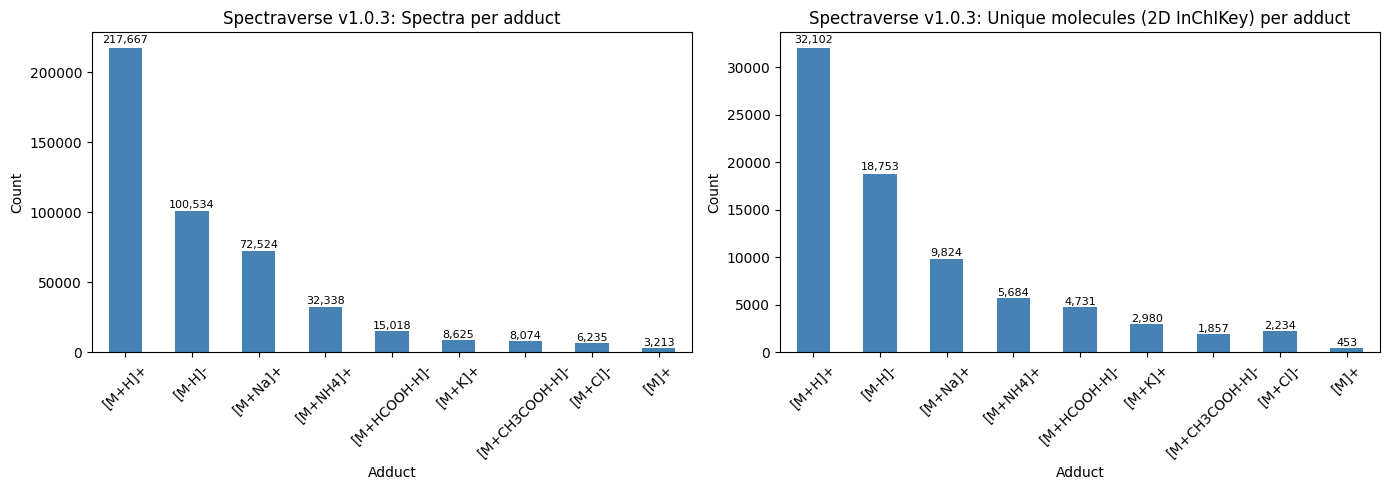

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in [
    (axes[0], "spectra", "Spectra per adduct"),
    (axes[1], "molecules", "Unique molecules (2D InChIKey) per adduct"),
]:
    vals = adduct_summary[col]
    vals.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Spectraverse v1.0.3: {title}")
    ax.set_xlabel("Adduct")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)
    for i, v in enumerate(vals):
        ax.text(i, v * 1.01, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

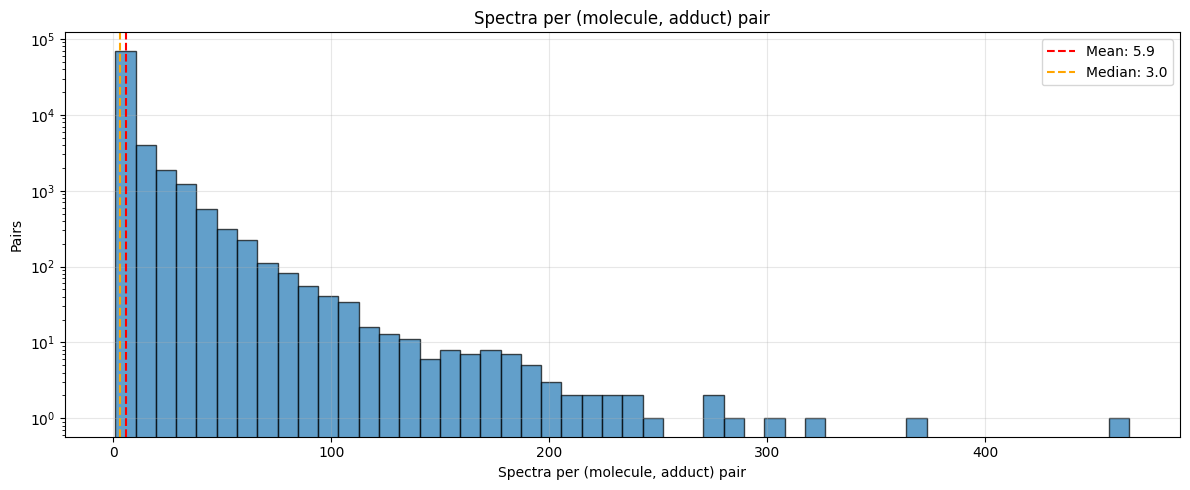

Total (molecule, adduct) pairs: 78,628
count    78628.00
mean         5.90
std         11.12
min          1.00
25%          1.00
50%          3.00
75%          5.00
max        466.00


In [7]:
spectra_per_mol_adduct = spectraverse_df.groupby(["mol_id", "prec_type"]).size()

plt.figure(figsize=(12, 5))
plt.hist(spectra_per_mol_adduct, bins=50, edgecolor="black", alpha=0.7)
plt.axvline(spectra_per_mol_adduct.mean(), color="red", linestyle="--",
            label=f"Mean: {spectra_per_mol_adduct.mean():.1f}")
plt.axvline(spectra_per_mol_adduct.median(), color="orange", linestyle="--",
            label=f"Median: {spectra_per_mol_adduct.median():.1f}")
plt.yscale("log")
plt.xlabel("Spectra per (molecule, adduct) pair")
plt.ylabel("Pairs")
plt.title("Spectra per (molecule, adduct) pair")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total (molecule, adduct) pairs: {len(spectra_per_mol_adduct):,}")
print(spectra_per_mol_adduct.describe().round(2).to_string())

## Collision energy

In [8]:
spec_with_ace = spectraverse_spec_df[spectraverse_spec_df["ace"].notnull()]
print(f"Spectra with ACE: {len(spec_with_ace):,} "
      f"({len(spec_with_ace) / len(spectraverse_spec_df):.1%})")
print(f"Spectra with NCE: {spectraverse_spec_df['nce'].notnull().sum():,}")
print(f"(mol_id, adduct) pairs with ACE: {spec_with_ace.groupby(['mol_id', 'prec_type']).ngroups:,}")

ace_by_adduct = pd.DataFrame({
    "spectra_with_ace": spec_with_ace["prec_type"].value_counts(),
    "frac_with_ace": (spec_with_ace["prec_type"].value_counts() / adduct_counts).round(3),
    "pairs_with_ace": spec_with_ace.groupby("prec_type")["mol_id"].nunique(),
}).reindex(ADDUCTS)
ace_by_adduct

Spectra with ACE: 232,506 (50.1%)
Spectra with NCE: 0
(mol_id, adduct) pairs with ACE: 42,815


,spectra_with_ace,frac_with_ace,pairs_with_ace
prec_type,,,
[M+H]+,117221,0.539,18379
[M-H]-,60351,0.600,12071
[M+Na]+,24875,0.343,3492
[M+NH4]+,7034,0.218,1877
[M+HCOOH-H]-,12001,0.799,3343
[M+K]+,2277,0.264,1192
[M+CH3COOH-H]-,982,0.122,421
[M+Cl]-,5242,0.841,1718
[M]+,2523,0.785,322


In [9]:
# ACE coverage by instrument type
pd.DataFrame({
    "spectra": spectraverse_spec_df["inst_type"].value_counts(),
    "with_ace": spec_with_ace["inst_type"].value_counts(),
}).fillna(0).astype(int).assign(frac=lambda d: (d["with_ace"] / d["spectra"]).round(3))

,spectra,with_ace,frac
inst_type,,,
NA,5942,4857,0.817
ORB,317727,175748,0.553
Other,20688,54,0.003
QTOF,119871,51847,0.433


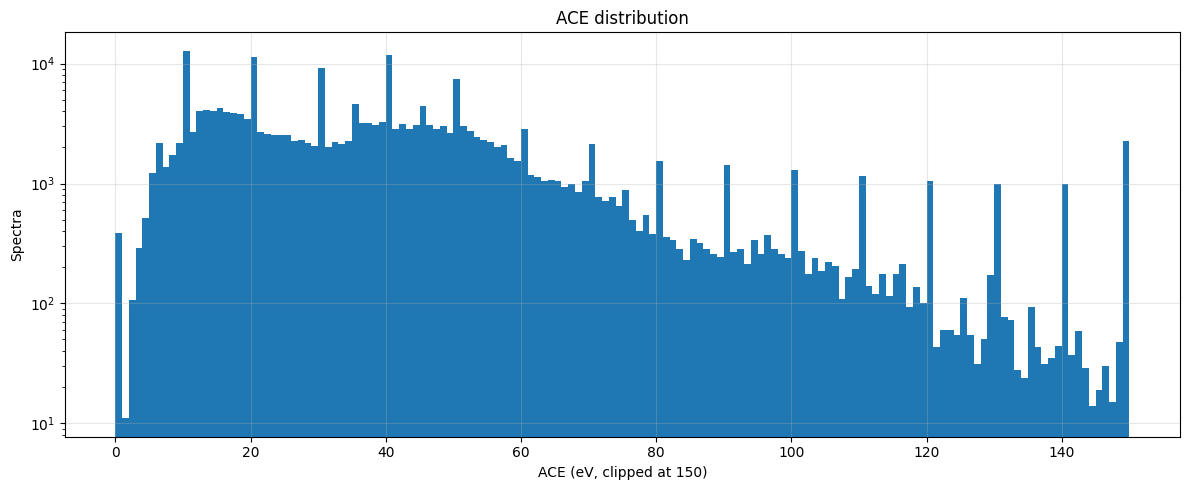

In [10]:
plt.figure(figsize=(12, 5))
plt.hist(spec_with_ace["ace"].clip(upper=150), bins=150, edgecolor="none")
plt.xlabel("ACE (eV, clipped at 150)")
plt.ylabel("Spectra")
plt.title("ACE distribution")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## v1.0.2 vs v1.0.3

Molecules are compared by 2D InChIKey; the two builds have independent `mol_id` values.

In [11]:
old_spec_df = pd.read_pickle(SPV_OLD_DP / "spec_df.pkl")[["mol_id", "prec_type"]]
old_mol_df = pd.read_pickle(SPV_OLD_DP / "mol_df.pkl")[["mol_id", "inchikey_s"]]
old_df = old_spec_df.merge(old_mol_df, on="mol_id", how="left")
del old_spec_df

version_cmp = pd.DataFrame({
    "spectra_1_0_2": old_df["prec_type"].value_counts(),
    "spectra_1_0_3": adduct_counts,
    "molecules_1_0_2": old_df.groupby("prec_type")["inchikey_s"].nunique(),
    "molecules_1_0_3": unique_mols_per_adduct,
}).reindex(ADDUCTS)
version_cmp.loc["total"] = [
    len(old_df), len(spectraverse_df),
    old_df["inchikey_s"].nunique(), spectraverse_df["inchikey_s"].nunique(),
]
version_cmp["spectra_change"] = version_cmp["spectra_1_0_3"] - version_cmp["spectra_1_0_2"]
version_cmp["molecule_change"] = version_cmp["molecules_1_0_3"] - version_cmp["molecules_1_0_2"]
version_cmp

,spectra_1_0_2,spectra_1_0_3,molecules_1_0_2,molecules_1_0_3,spectra_change,molecule_change
prec_type,,,,,,
[M+H]+,233103,217667,32014,32102,-15436,88
[M-H]-,107867,100534,18718,18753,-7333,35
[M+Na]+,69475,72524,9121,9824,3049,703
[M+NH4]+,34889,32338,5596,5684,-2551,88
[M+HCOOH-H]-,16136,15018,4607,4731,-1118,124
[M+K]+,9508,8625,2722,2980,-883,258
[M+CH3COOH-H]-,8456,8074,1843,1857,-382,14
[M+Cl]-,5958,6235,2117,2234,277,117
[M]+,3405,3213,455,453,-192,-2


In [12]:
ik_old = set(old_df["inchikey_s"])
ik_new = set(spectraverse_df["inchikey_s"])
print(f"InChIKeys in both:          {len(ik_old & ik_new):,}")
print(f"Only in v1.0.2 (removed):   {len(ik_old - ik_new):,}")
print(f"Only in v1.0.3 (added):     {len(ik_new - ik_old):,}")
n_added_spec = spectraverse_df["inchikey_s"].isin(ik_new - ik_old).sum()
n_removed_spec = old_df["inchikey_s"].isin(ik_old - ik_new).sum()
print(f"v1.0.3 spectra of added molecules:   {n_added_spec:,}")
print(f"v1.0.2 spectra of removed molecules: {n_removed_spec:,}")

InChIKeys in both:          44,234
Only in v1.0.2 (removed):   0
Only in v1.0.3 (added):     0
v1.0.3 spectra of added molecules:   0
v1.0.2 spectra of removed molecules: 0


## Benchmark folds

Each cv uses the MGF `FOLD` field: one fold for test, fold 10 for val, the rest for train
(`stats.json` in each cv directory).

In [13]:
rows = []
for cv_dp in sorted(SPLIT_DP.glob("cv*"), key=lambda p: int(p.name[2:])):
    st = json.loads((cv_dp / "stats.json").read_text())
    rows.append({
        "cv": st["cv"],
        "test_fold": st["folds"]["test"],
        "val_fold": st["folds"]["val"],
        **{f"{k}_spectra": v for k, v in st["num_spectra"].items()},
        **{f"{k}_molecules": v for k, v in st["num_molecules"].items()},
        "mgf_md5": st["mgf_md5"],
    })
fold_df = pd.DataFrame(rows).set_index("cv")
assert (fold_df["mgf_md5"] == "52ed27db2d5b764a636fb2ce246004aa").all()
fold_df.drop(columns="mgf_md5")

,test_fold,val_fold,train_spectra,val_spectra,test_spectra,train_molecules,val_molecules,test_molecules
cv,,,,,,,,
0,1,10,367561,43895,52772,33916,4239,6079
1,2,1,367274,52772,44182,33735,6079,4420
2,3,2,374473,44182,45573,35398,4420,4416
3,4,3,365982,45573,52673,35579,4416,4239
4,5,4,368180,52673,43375,35755,4239,4240
5,6,5,378735,43375,42118,35754,4240,4240
6,7,6,372811,42118,49299,35755,4240,4239
7,8,7,370345,49299,44584,35932,4239,4063
8,9,8,373887,44584,45757,36112,4063,4059


In [14]:
# Adduct composition of each cv's test set (fraction of spectra)
test_comp = {}
for cv_dp in sorted(SPLIT_DP.glob("cv*"), key=lambda p: int(p.name[2:])):
    ids = pd.read_csv(cv_dp / "test_ids.csv", usecols=["spec_id"])
    sub = spectraverse_spec_df[spectraverse_spec_df["spec_id"].astype(int).isin(ids["spec_id"])]
    assert len(sub) == len(ids)
    test_comp[cv_dp.name] = sub["prec_type"].value_counts(normalize=True)
pd.DataFrame(test_comp).reindex(ADDUCTS).round(3)

,cv0,cv1,cv2,cv3,cv4,cv5,cv6,cv7,cv8,cv9
prec_type,,,,,,,,,,
[M+H]+,0.472,0.434,0.360,0.480,0.486,0.463,0.494,0.495,0.507,0.493
[M-H]-,0.266,0.354,0.134,0.217,0.179,0.248,0.186,0.188,0.177,0.214
[M+Na]+,0.103,0.062,0.133,0.200,0.182,0.149,0.189,0.190,0.187,0.166
[M+NH4]+,0.089,0.010,0.308,0.029,0.039,0.061,0.047,0.034,0.036,0.044
[M+HCOOH-H]-,0.005,0.022,0.031,0.031,0.047,0.038,0.036,0.042,0.039,0.038
[M+K]+,0.014,0.004,0.015,0.021,0.023,0.019,0.024,0.022,0.022,0.022
[M+CH3COOH-H]-,0.031,0.101,0.000,0.001,0.025,0.001,0.001,0.001,0.014,0.000
[M+Cl]-,0.002,0.009,0.014,0.014,0.017,0.016,0.016,0.017,0.016,0.015
[M]+,0.018,0.004,0.005,0.007,0.003,0.004,0.006,0.010,0.003,0.008


## Spectral entropy and peak count

In [15]:
import ms_entropy as me
from tqdm.auto import tqdm

tqdm.pandas(desc="Entropy")
spectraverse_spec_df["ms_entropy"] = spectraverse_spec_df["peaks"].progress_apply(
    lambda peaks: me.calculate_spectral_entropy(
        np.array(peaks), clean_spectrum=True, min_ms2_difference_in_da=0.05
    )
)
spectraverse_spec_df["num_peaks"] = spectraverse_spec_df["peaks"].apply(len)

Entropy:   0%|          | 0/464228 [00:00<?, ?it/s]

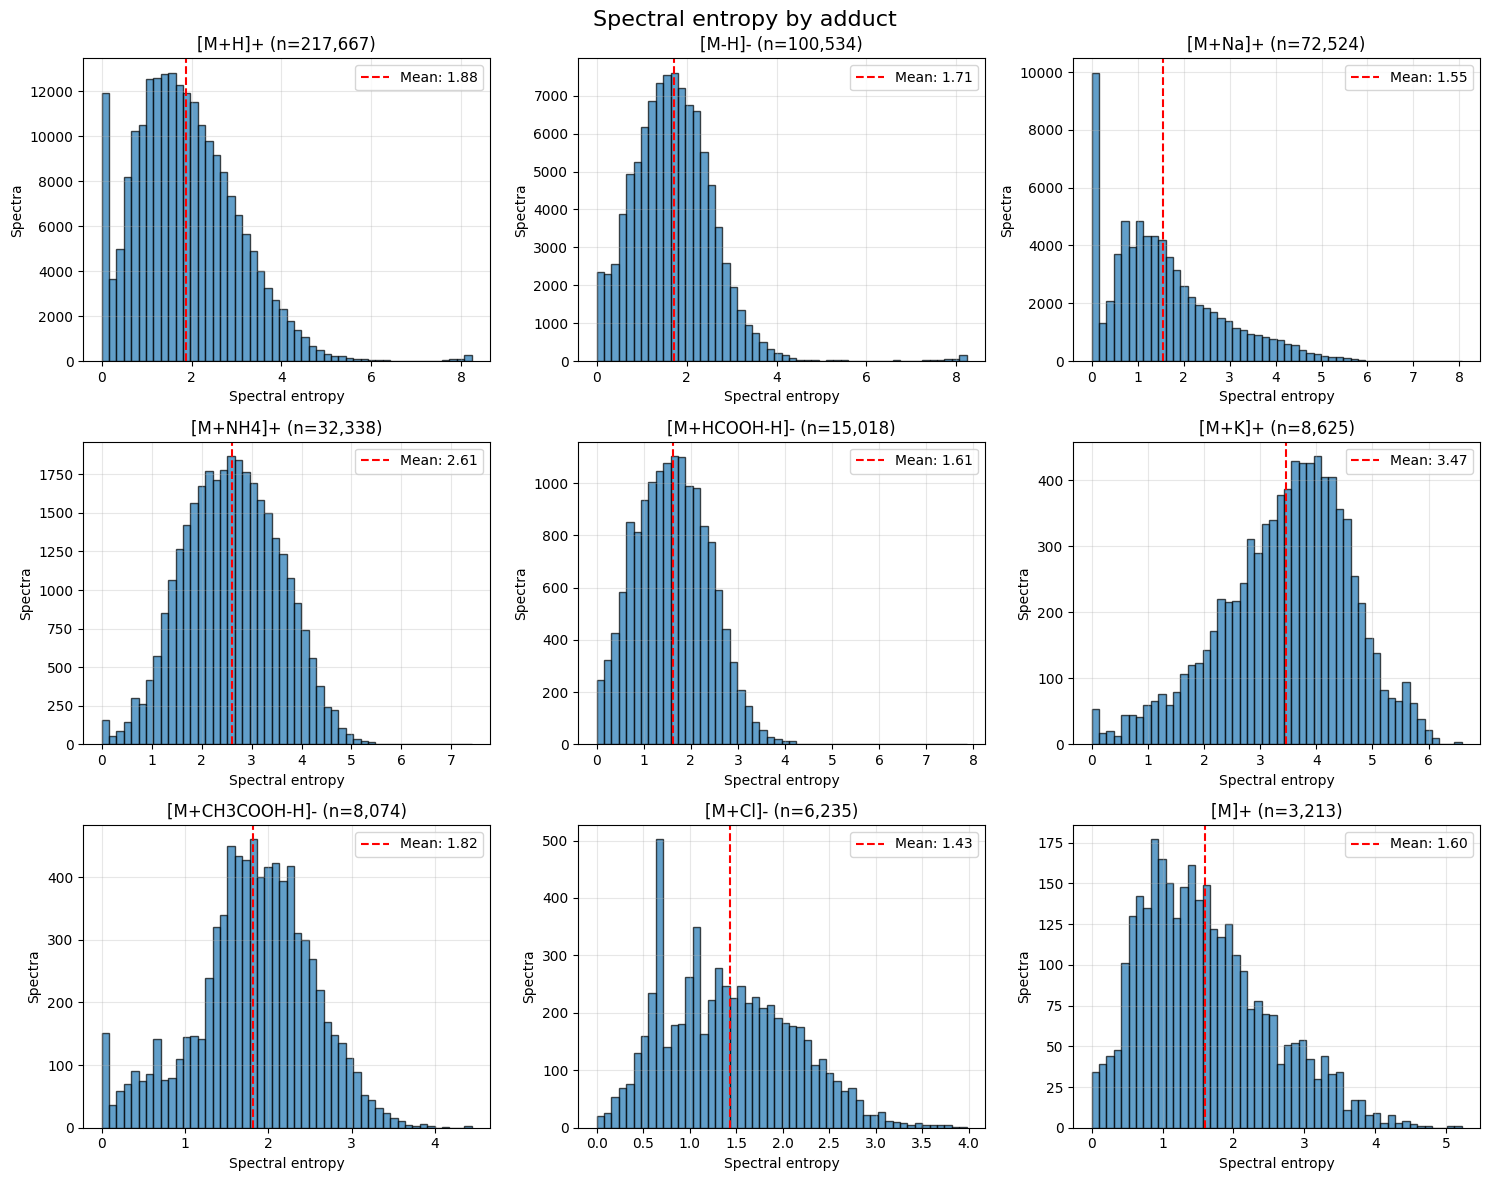

ms_entropy               num_peaks                
                     mean    std median      mean      std median
prec_type                                                        
[M+H]+              1.878  1.140  1.760    73.120  249.360   24.0
[M-H]-              1.711  0.916  1.667    56.461  254.556   21.0
[M+Na]+             1.551  1.212  1.331    46.941  121.621   10.0
[M+NH4]+            2.607  0.953  2.600   139.326  276.304   61.0
[M+HCOOH-H]-        1.615  0.779  1.598    26.657   81.976   15.0
[M+K]+              3.470  1.145  3.601   262.605  251.364  214.0
[M+CH3COOH-H]-      1.821  0.709  1.855    62.508   94.339   28.0
[M+Cl]-             1.429  0.695  1.372    13.120   16.371    8.0
[M]+                1.602  0.897  1.463    30.918   82.602   10.0

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, adduct in zip(axes.flatten(), ADDUCTS):
    vals = spectraverse_spec_df.loc[spectraverse_spec_df["prec_type"] == adduct, "ms_entropy"]
    ax.hist(vals, bins=50, alpha=0.7, edgecolor="black")
    ax.axvline(vals.mean(), color="red", linestyle="--", label=f"Mean: {vals.mean():.2f}")
    ax.set_title(f"{adduct} (n={len(vals):,})")
    ax.set_xlabel("Spectral entropy")
    ax.set_ylabel("Spectra")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.suptitle("Spectral entropy by adduct", fontsize=16)
plt.tight_layout()
plt.show()

spectraverse_spec_df.groupby("prec_type")[["ms_entropy", "num_peaks"]].agg(
    ["mean", "std", "median"]
).reindex(ADDUCTS).round(3)

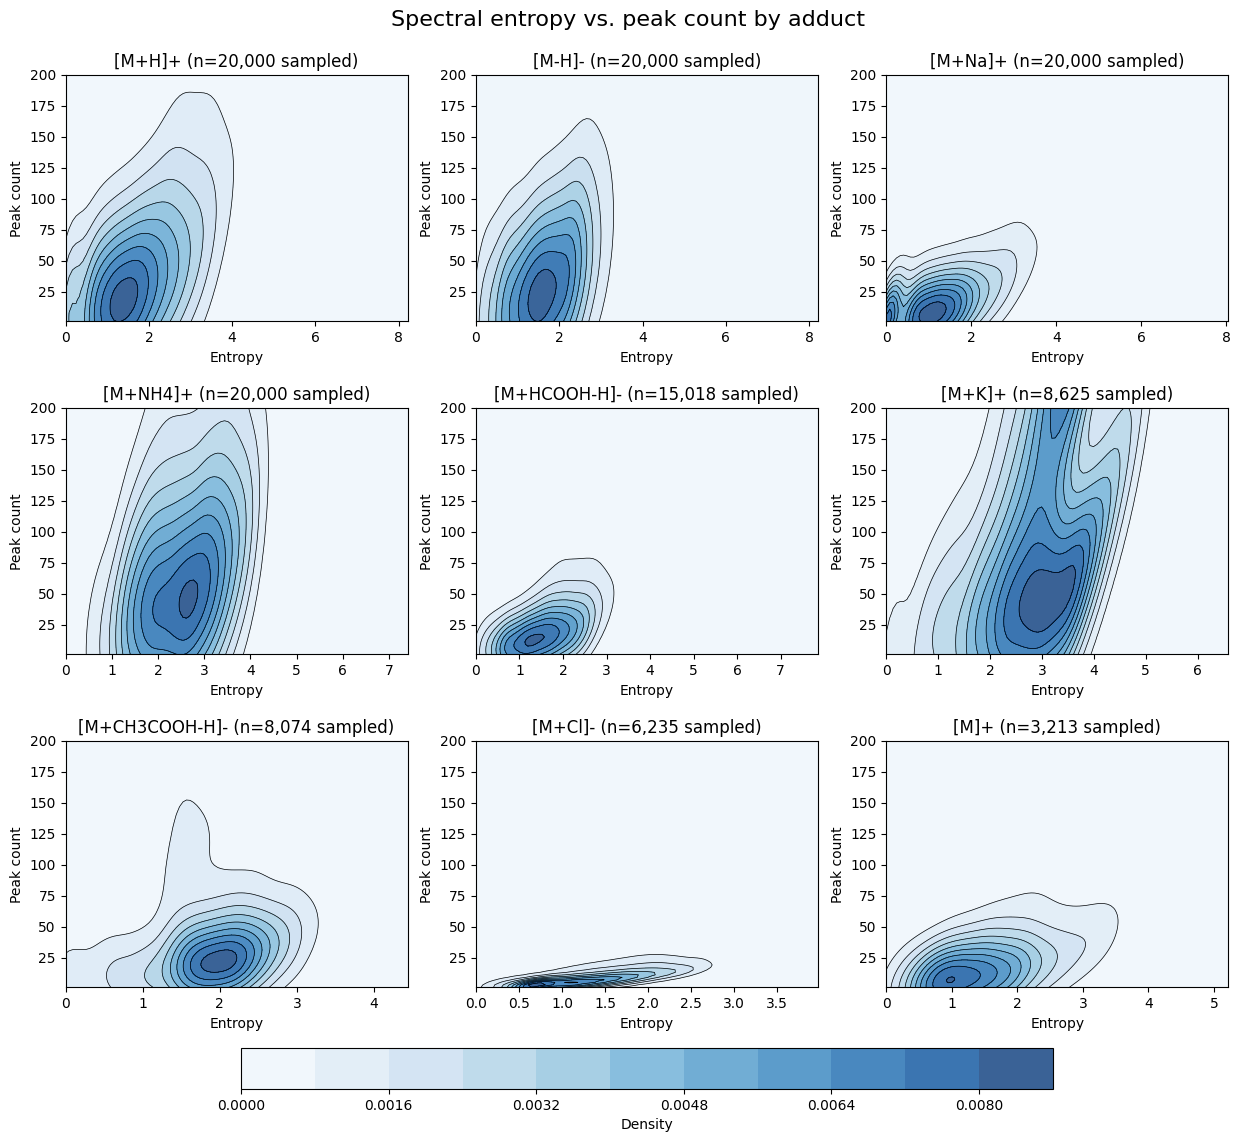

In [17]:
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
contourf_handles = []
for ax, adduct in zip(axes.flatten(), ADDUCTS):
    sub = spectraverse_spec_df[spectraverse_spec_df["prec_type"] == adduct]
    sub = sub.sample(n=min(20_000, len(sub)), random_state=0)
    entropy = sub["ms_entropy"].values
    peak_num = sub["num_peaks"].values
    kernel = gaussian_kde(np.vstack([entropy, peak_num]))
    y_max = min(peak_num.max(), 200)
    X, Y = np.mgrid[entropy.min():entropy.max():100j, peak_num.min():y_max:100j]
    Z = kernel(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    cf = ax.contourf(X, Y, Z, levels=10, cmap="Blues", alpha=0.8)
    ax.contour(X, Y, Z, levels=10, colors="black", linewidths=0.5)
    ax.set_xlabel("Entropy")
    ax.set_ylabel("Peak count")
    ax.set_title(f"{adduct} (n={len(sub):,} sampled)")
    contourf_handles.append(cf)
fig.subplots_adjust(top=0.93, bottom=0.15, hspace=0.35)
cbar = fig.colorbar(contourf_handles[-1], ax=axes, orientation="horizontal", fraction=0.04, pad=0.06)
cbar.set_label("Density")
fig.suptitle("Spectral entropy vs. peak count by adduct", fontsize=16)
plt.show()

## Overlap with NIST HR libraries

Molecules (2D InChIKey) in Spectraverse v1.0.3 that are absent from NIST20 HR (`nist20_hr`) or
NIST23 HR (`nist23_hr1`, `nist23_hr2`). MoNA rows stored beside NIST are excluded.

In [18]:
def nist_hr_inchikeys(proc_dp, dsets):
    spec = pd.read_pickle(proc_dp / "spec_df.pkl")[["mol_id", "dset"]]
    mol_ids = spec.loc[spec["dset"].isin(dsets), "mol_id"].unique()
    del spec
    mol = pd.read_pickle(proc_dp / "mol_df.pkl")[["mol_id", "inchikey_s"]]
    return set(mol.loc[mol["mol_id"].isin(mol_ids), "inchikey_s"])


def novel_summary(ref_inchikeys, ref_name):
    novel = spectraverse_df[~spectraverse_df["inchikey_s"].isin(ref_inchikeys)]
    novel_ace = novel[novel["ace"].notnull()]
    print(f"Spectraverse molecules not in {ref_name}: {novel['inchikey_s'].nunique():,} "
          f"of {spectraverse_df['inchikey_s'].nunique():,}")
    print(f"Spectra of those molecules: {len(novel):,} (with ACE: {len(novel_ace):,})")
    return pd.DataFrame({
        "spectra": novel["prec_type"].value_counts(),
        "molecules": novel.groupby("prec_type")["inchikey_s"].nunique(),
        "spectra_with_ace": novel_ace["prec_type"].value_counts(),
        "pairs_with_ace": novel_ace.groupby("prec_type")["mol_id"].nunique(),
    }).reindex(ADDUCTS).fillna(0).astype(int)


nist20_hr_inchikeys = nist_hr_inchikeys(DATA / "proc/nist20", ["nist20_hr"])
print(f"NIST20 HR molecules: {len(nist20_hr_inchikeys):,}")
novel_summary(nist20_hr_inchikeys, "NIST20 HR")

NIST20 HR molecules: 26,798
Spectraverse molecules not in NIST20 HR: 35,538 of 44,234
Spectra of those molecules: 257,037 (with ACE: 122,284)


,spectra,molecules,spectra_with_ace,pairs_with_ace
prec_type,,,,
[M+H]+,118347,24497,62663,12790
[M-H]-,56222,13607,33638,7970
[M+Na]+,35027,6045,9414,1593
[M+NH4]+,21798,3781,2003,583
[M+HCOOH-H]-,9168,3214,7140,2143
[M+K]+,2174,1032,486,278
[M+CH3COOH-H]-,7038,1752,896,389
[M+Cl]-,4309,1597,3623,1207
[M]+,2954,414,2421,294


In [19]:
nist23_hr_inchikeys = nist_hr_inchikeys(DATA / "proc/nist23", ["nist23_hr1", "nist23_hr2"])
print(f"NIST23 HR molecules: {len(nist23_hr_inchikeys):,}")
novel_summary(nist23_hr_inchikeys, "NIST23 HR")

NIST23 HR molecules: 44,829
Spectraverse molecules not in NIST23 HR: 34,417 of 44,234
Spectra of those molecules: 258,372 (with ACE: 120,135)


,spectra,molecules,spectra_with_ace,pairs_with_ace
prec_type,,,,
[M+H]+,118552,23709,62212,12322
[M-H]-,56224,13209,32102,7549
[M+Na]+,36218,6045,9915,1632
[M+NH4]+,22307,3826,2401,647
[M+HCOOH-H]-,9352,3212,7222,2123
[M+K]+,2504,1081,578,323
[M+CH3COOH-H]-,7195,1765,916,396
[M+Cl]-,4144,1544,3431,1148
[M]+,1876,307,1358,187
